# П2 (пара B): Score SDE на 2D-данных

**Задание.**
1. Обучить score-сеть на VE- и VP-SDE (denoising score matching с непрерывным $t$).
2. Сравнить обратное SDE (Эйлер–Маруяма) и probability flow ODE (Эйлер) при одинаковом числе шагов, NFE от 10 до 1000: кривая «качество vs NFE».
3. Посчитать log-likelihood через probability flow ODE и сравнить с истинным $\log p$ смеси; дивергенция точно через autograd и оценкой Хатчинсона.

**Готово, когда:** есть кривая качества по NFE для SDE и ODE и график «посчитанное vs истинное $\log p$».

Во всех экспериментах рядом с обученной сетью запускаем **точный score оракула**: данные — смесь гауссиан, поэтому $\nabla\log p_t$ известен в замкнутом виде. Разница «сеть vs оракул» — ошибка модели; изменение с NFE — ошибка дискретизации.

**Формулы** (Song et al., 2021):
* прямое SDE: $dx = f(x,t)\,dt + g(t)\,dW$;
* обратное SDE: $dx = [f - g^2\nabla\log p_t]\,dt + g\,d\bar W$, от $T$ к $0$;
* probability flow ODE: $dx = [f - \tfrac12 g^2\nabla\log p_t]\,dt$;
* лосс: $\mathbb E_{t, x_0, z}\,\|\mathrm{std}(t)\, s_\theta(x_t, t) + z\|^2$, где $x_t = \alpha(t)x_0 + \mathrm{std}(t)\,z$.

**Как устроен код.** Все долгие вычисления — функции в `p2_experiments.py`. Ноутбук вызывает их через `load_or_run`: если результат уже лежит в `results/` или `checkpoints/`, он просто загружается. Поэтому ноутбук перезапускается за пару минут. Пересчитать всё с нуля: удалить папки `results/` и `checkpoints/` (около 30 минут на CPU).

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
from p2_experiments import (EPS, NFES, SEEDS, N_EVAL, SDES, mix, load_or_run, load_model, oracle_score,
                            sweep, metric_floor, loglik, hutchinson_vs_k)
from common.sde import perturb
from common.samplers import sample_reverse_sde, sample_pf_ode

torch.manual_seed(0)
print('веса мод:', mix.weights.numpy().round(3))
print('NFE:', NFES, '| сидов:', len(SEEDS), '| точек на запуск:', N_EVAL)

веса мод: [0.25 0.05 0.15 0.05 0.2  0.05 0.2  0.05]
NFE: [10, 20, 50, 100, 200, 500, 1000] | сидов: 3 | точек на запуск: 10000


## 0. Данные и прямой процесс

Смесь 8 гауссиан (радиус 3, std 0.25) с **неравными весами**: кроме формы распределения проверяем, правильно ли восстанавливаются доли мод.

* **VE:** $dx = \sqrt{d\sigma^2/dt}\,dW$, $\sigma(t) = 0.01\cdot 1000^t$. Точки остаются на месте, шум растёт до $\sigma_{\max}=10$: дисперсия «взрывается».
* **VP:** $dx = -\tfrac12\beta(t)x\,dt + \sqrt{\beta(t)}\,dW$, $\beta(t) = 0.1 + 19.9t$. Точки сжимаются к нулю, в конце $\mathcal N(0, I)$.

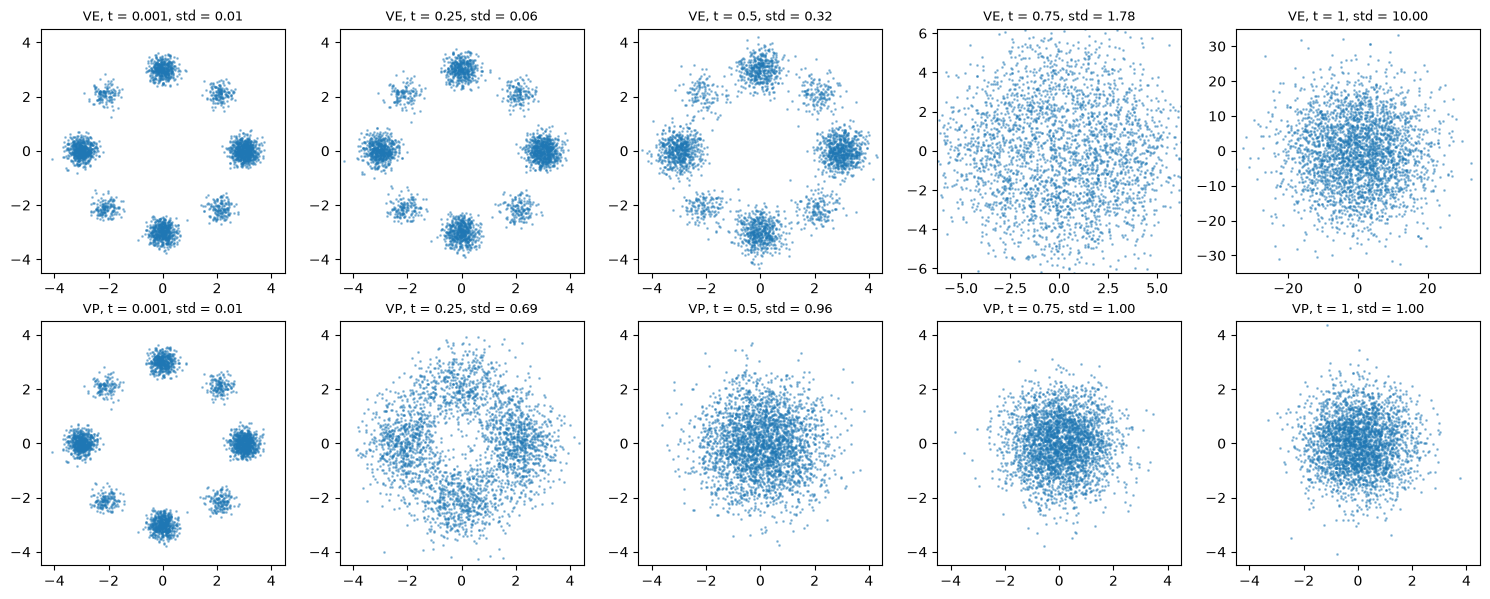

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
x0 = mix.sample(3000, generator=torch.Generator().manual_seed(0))
for row, (name, sde) in enumerate(SDES.items()):
    for col, t in enumerate([EPS, 0.25, 0.5, 0.75, 1.0]):
        xt, _, _ = perturb(sde, x0, torch.full((len(x0),), t))
        std = float(sde.std(torch.tensor(t)))
        lim = 4.5 if name == 'VP' else max(4.5, 3.5 * std)
        ax = axes[row, col]; ax.scatter(*xt.T, s=1, alpha=0.4)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
        ax.set_title(f'{name}, t = {t:g}, std = {std:.2f}', fontsize=9)
plt.tight_layout(); plt.savefig('figures/p2_forward.png', dpi=130); plt.show()

## 1. Обучение: denoising score matching с непрерывным $t$

Уравнение (7) статьи: $t \sim U[\varepsilon, 1]$, $x_0$ из данных, $x_t = \alpha(t)x_0 + \mathrm{std}(t)z$, цель — score ядра $-z/\mathrm{std}(t)$.

Сеть предсказывает шум: $s_\theta(x,t) = -\hat\varepsilon_\theta(x,t)/\mathrm{std}(t)$. С весом $\lambda(t) = \mathrm{std}(t)^2$ лосс становится $\|\hat\varepsilon_\theta(x_t,t) - z\|^2$, как в DDPM. Это правило статьи $\lambda \propto 1/\mathbb E\|\nabla\log p_{0t}\|^2$: все $t$ дают вклад одного масштаба.

MLP 4×256 + синусоидальный эмбеддинг времени, Adam (lr 2e-3, косинусное расписание), батч 1024, 10 000 шагов, EMA весов 0.999. Данные сэмплируются заново на каждом шаге.

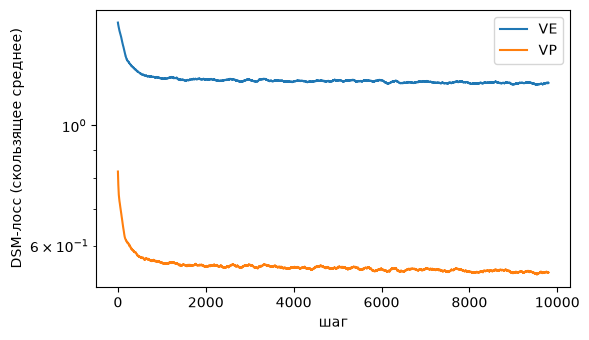

VE: финальный лосс 1.195
VP: финальный лосс 0.535


In [3]:
models, losses = {}, {}
for name in SDES:
    models[name], losses[name] = load_model(name)      # обучит, если чекпоинта нет (~2.5 мин)

plt.figure(figsize=(6, 3.5))
for name in SDES:
    plt.plot(np.convolve(losses[name], np.ones(200) / 200, mode='valid'), label=name)
plt.yscale('log'); plt.xlabel('шаг'); plt.ylabel('DSM-лосс (скользящее среднее)'); plt.legend()
plt.tight_layout(); plt.savefig('figures/p2_loss.png', dpi=130); plt.show()
for name in SDES:
    print(f'{name}: финальный лосс {np.mean(losses[name][-500:]):.3f}')

**Почему лосс не уходит в ноль.** В одну точку $x_t$ попадают зашумлённые версии разных $x_0$, и шум $z$ по $x_t$ полностью не угадать. Минимум лосса — это неустранимая дисперсия (та самая константа $C$ из доказательства DSM ≡ SM), а не ноль. У VE она больше: при больших $\sigma$ точки разных мод сильнее перемешаны. Поэтому качество проверяем не по лоссу, а сравнением с оракулом.

### Проверка: выученный score против точного

Относительная ошибка $\mathbb E_{x\sim p_t}\|s_\theta - \nabla\log p_t\|^2 / \mathbb E_{x\sim p_t}\|\nabla\log p_t\|^2$ для разных $t$.

VE: средняя относительная ошибка score 0.0094, максимум 0.1016 при t = 0.001
VP: средняя относительная ошибка score 0.0851, максимум 2.5347 при t = 0.001


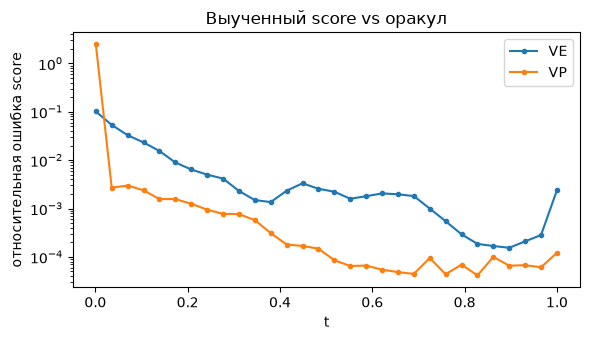

In [4]:
ts_check = torch.linspace(EPS, 1.0, 30)
plt.figure(figsize=(6, 3.5))
for name, sde in SDES.items():
    rel = []
    for t in ts_check:
        xt, _, _ = perturb(sde, mix.sample(4000, generator=torch.Generator().manual_seed(3)),
                           torch.full((4000,), float(t)), generator=torch.Generator().manual_seed(4))
        s_true = oracle_score(sde)(xt, t)
        s_hat = models[name].score(xt, t)
        rel.append((((s_hat - s_true) ** 2).sum(1).mean() / (s_true ** 2).sum(1).mean()).item())
    plt.plot(ts_check, rel, 'o-', ms=3, label=name)
    print(f'{name}: средняя относительная ошибка score {np.mean(rel):.4f}, '
          f'максимум {np.max(rel):.4f} при t = {ts_check[int(np.argmax(rel))]:.3f}')
plt.yscale('log'); plt.xlabel('t'); plt.ylabel('относительная ошибка score'); plt.legend()
plt.title('Выученный score vs оракул'); plt.tight_layout(); plt.savefig('figures/p2_score_error.png', dpi=130); plt.show()

## 2. Обратное SDE vs probability flow ODE: качество по NFE

Для каждого NFE $\in\{10, 20, 50, 100, 200, 500, 1000\}$ генерируем $10^4$ точек на одной и той же равномерной сетке от $T=1$ до $\varepsilon$:
* **обратное SDE** — Эйлер–Маруяма (на последнем шаге шум не добавляем);
* **probability flow ODE** — Эйлер.

Метрики:
* **Sliced Wasserstein-1** до фиксированной выборки из данных. Серая полоса — «пол» метрики: SW между двумя независимыми выборками из самих данных. Лучше этого конечная выборка не даст.
* **TV по долям мод** $\tfrac12\sum_k|\hat w_k - w_k|$ — насколько правильно восстановлены веса мод.

Каждая точка — среднее по 3 сидам, усики — стандартное отклонение.

пол SW1: 0.0337 ± 0.0098;  пол TV мод: 0.0103


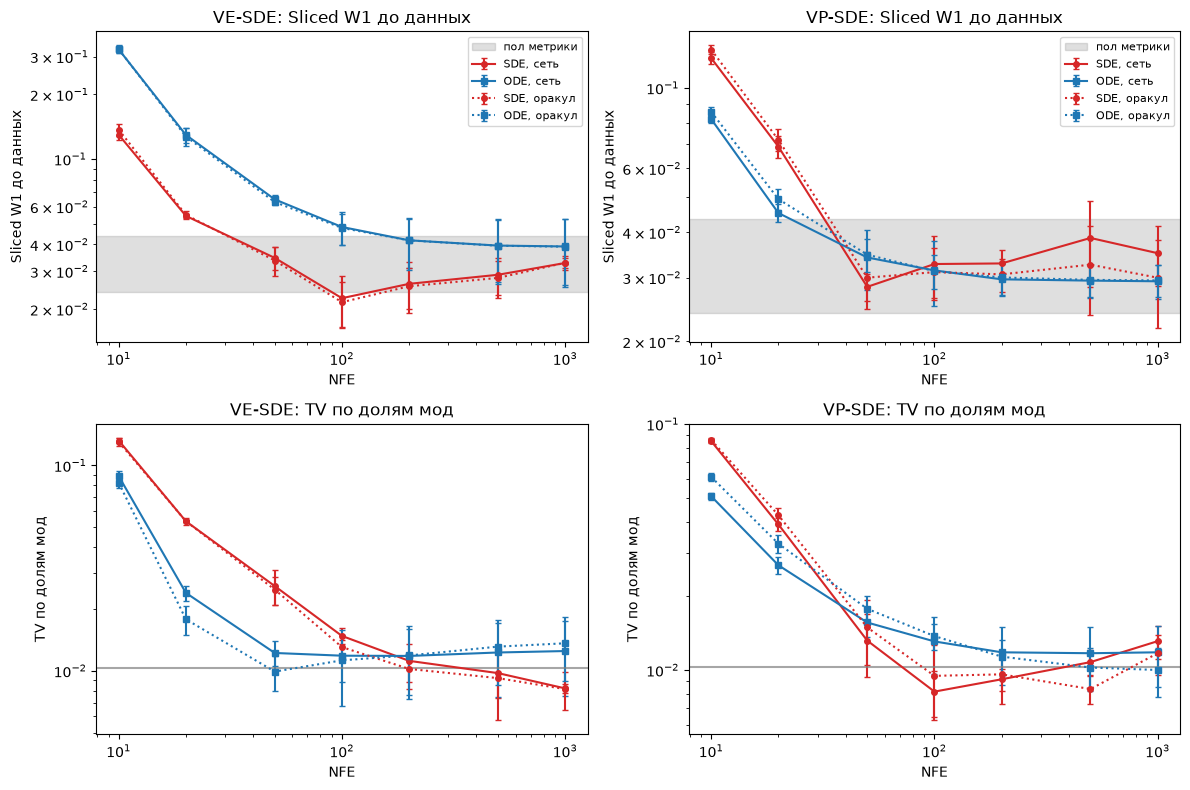

Sliced W1 (среднее по сидам)
                          10      20      50     100     200     500    1000
VE SDE сеть   :       0.130   0.054   0.035   0.022   0.026   0.029   0.033
VE SDE оракул :       0.137   0.055   0.034   0.022   0.026   0.028   0.033
VE ODE сеть   :       0.324   0.129   0.065   0.048   0.042   0.040   0.039
VE ODE оракул :       0.325   0.127   0.063   0.048   0.042   0.039   0.039
VP SDE сеть   :       0.121   0.069   0.028   0.033   0.033   0.039   0.035
VP SDE оракул :       0.127   0.072   0.030   0.031   0.031   0.033   0.030
VP ODE сеть   :       0.082   0.045   0.034   0.031   0.030   0.029   0.029
VP ODE оракул :       0.086   0.049   0.035   0.031   0.030   0.030   0.029


In [5]:
floor = load_or_run('results/floor.pt', metric_floor)
res = {(n, s): load_or_run(f'results/sweep_{n}_{s}.pt', sweep, n, s) for n in SDES for s in ['SDE', 'ODE']}
print(f"пол SW1: {floor['sw'].mean():.4f} ± {floor['sw'].std():.4f};  пол TV мод: {floor['tv'].mean():.4f}")

styles = {('сеть', 'SDE'): ('C3', '-', 'o'), ('сеть', 'ODE'): ('C0', '-', 's'),
          ('оракул', 'SDE'): ('C3', ':', 'o'), ('оракул', 'ODE'): ('C0', ':', 's')}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, name in enumerate(SDES):
    for (src, samp), (c, ls, mk) in styles.items():
        r = res[(name, samp)][src]
        axes[0, col].errorbar(NFES, r['sw'].mean(1), yerr=r['sw'].std(1), color=c, ls=ls, marker=mk, ms=4,
                              capsize=2, label=f'{samp}, {src}')
        axes[1, col].errorbar(NFES, r['tv'].mean(1), yerr=r['tv'].std(1), color=c, ls=ls, marker=mk, ms=4,
                              capsize=2, label=f'{samp}, {src}')
    fm, fs = floor['sw'].mean(), floor['sw'].std()
    axes[0, col].axhspan(fm - fs, fm + fs, color='gray', alpha=0.25, label='пол метрики')
    axes[1, col].axhline(floor['tv'].mean(), color='gray', alpha=0.7, label='пол метрики')
    for row, lab in enumerate(['Sliced W1 до данных', 'TV по долям мод']):
        ax = axes[row, col]; ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_xlabel('NFE'); ax.set_ylabel(lab); ax.set_title(f'{name}-SDE: {lab}')
    axes[0, col].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/p2_quality_vs_nfe.png', dpi=150); plt.show()

print('Sliced W1 (среднее по сидам)')
print(f"{'':20}" + ''.join(f'{n:>8}' for n in NFES))
for (name, samp), r in res.items():
    for src in ['сеть', 'оракул']:
        print(f'{name} {samp} {src:7}:    ' + ''.join(f"{v:8.3f}" for v in r[src]['sw'].mean(1)))

### Как выглядят сэмплы

Обученная сеть, NFE = 10, 50, 1000.

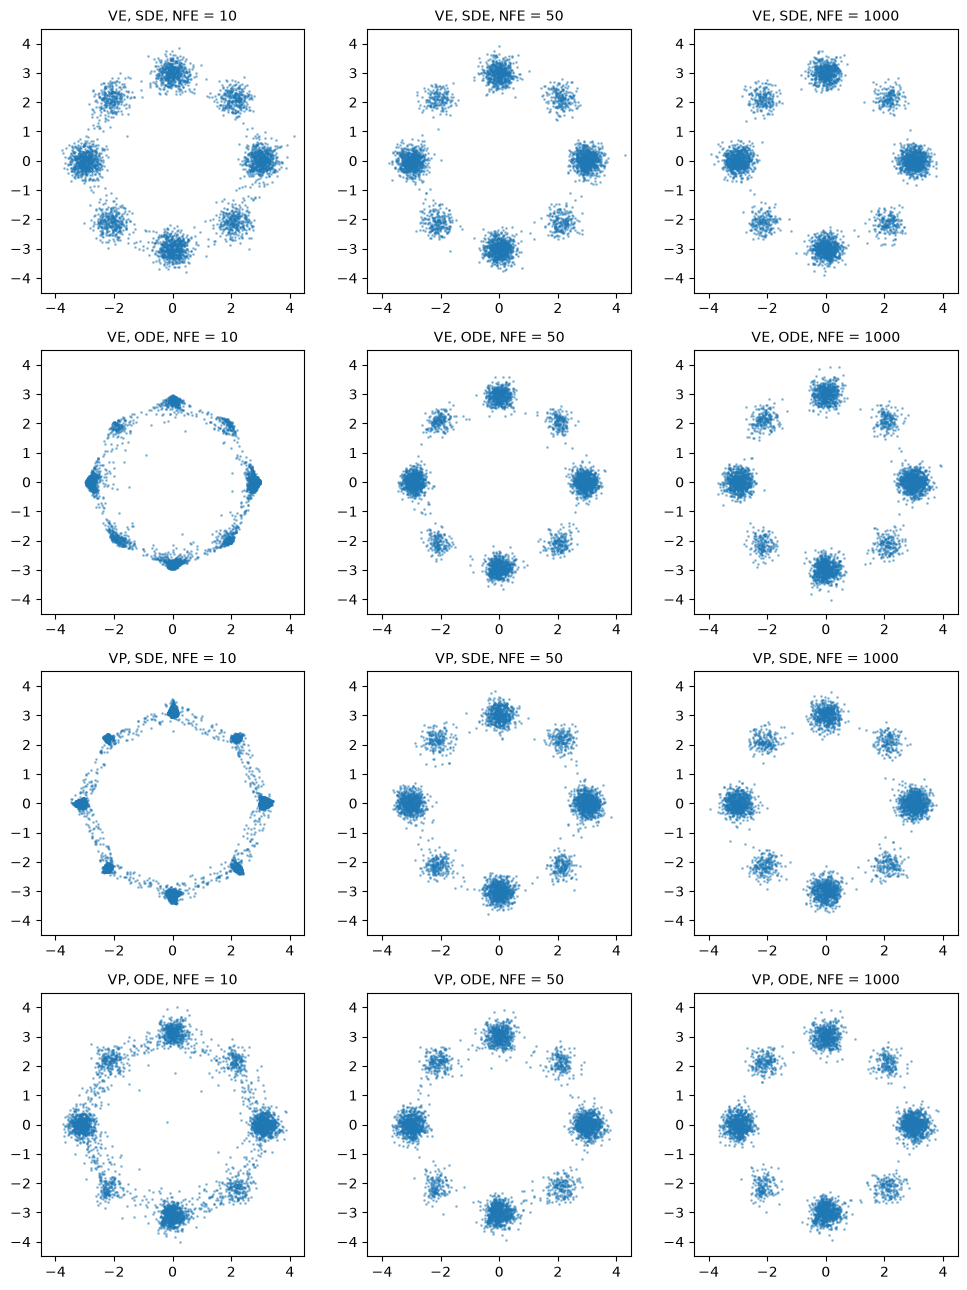

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(10, 13))
row = 0
for name, sde in SDES.items():
    for samp, sampler in [('SDE', sample_reverse_sde), ('ODE', sample_pf_ode)]:
        for k, nfe in enumerate([10, 50, 1000]):
            x = sampler(sde, models[name].score, 4000, nfe, eps=EPS, generator=torch.Generator().manual_seed(0))
            ax = axes[row, k]
            ax.scatter(*x.T, s=1, alpha=0.4); ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect('equal')
            ax.set_title(f'{name}, {samp}, NFE = {nfe}', fontsize=10)
        row += 1
plt.tight_layout(); plt.savefig('figures/p2_samples.png', dpi=120); plt.show()

## 3. Log-likelihood через probability flow ODE

Приложение D статьи. Вдоль решения ODE $dx = F(x,t)\,dt$ плотность меняется по формуле мгновенной замены переменных
$$\frac{d}{dt}\log p_t(x(t)) = -\nabla\cdot F(x(t), t),$$
поэтому, интегрируя ODE **вперёд** от $\varepsilon$ до $T$,
$$\log p_\varepsilon(x) = \log p_T(x(T)) + \int_\varepsilon^T \nabla\cdot F(x(t),t)\,dt, \qquad F = f - \tfrac12 g^2 s_\theta .$$

$\log p_T$ — плотность приора: $\mathcal N(0, I)$ для VP и $\mathcal N(0, \sigma_{\max}^2 I)$ для VE. Сравниваем с **истинным** $\log p_\varepsilon$ смеси на 2000 тестовых точках из $p_\varepsilon$.

Дивергенция:
* **точно** — $\sum_i \partial F_i/\partial x_i$, в 2D это два прохода autograd;
* **Хатчинсон** — $\nabla\cdot F \approx v^\top (\partial F/\partial x)\, v$, $v$ — вектор Радемахера ($\pm1$), фиксированный вдоль траектории; один проход autograd.

Интегрирование — Эйлер, 1000 шагов. Контроль: то же с точным score оракула. Так видно, какая часть ошибки идёт от схемы интегрирования, а какая — от сети.

In [7]:
ll = {name: load_or_run(f'results/loglik_{name}.pt', loglik, name) for name in SDES}

print(f"{'':5}{'NLL истинный':>14}{'сеть, точно':>13}{'сеть, Хатч.':>13}{'оракул':>9}"
      f"{'MAE сети':>10}{'MAE Хатч.':>11}{'MAE оракула':>13}{'корр.':>8}")
for name, r in ll.items():
    mae = lambda k: (r[k] - r['true']).abs().mean().item()
    corr = np.corrcoef(r['model'].numpy(), r['true'].numpy())[0, 1]
    print(f"{name:5}{-r['true'].mean():14.3f}{-r['model'].mean():13.3f}{-r['model_h'].mean():13.3f}"
          f"{-r['oracle'].mean():9.3f}{mae('model'):10.3f}{mae('model_h'):11.3f}{mae('oracle'):13.3f}{corr:8.4f}")

       NLL истинный  сеть, точно  сеть, Хатч.   оракул  MAE сети  MAE Хатч.  MAE оракула   корр.
VE            1.908        1.909        1.928    1.891     0.126      0.832        0.031  0.9890
VP            1.908        1.920        1.935    1.901     0.137      0.847        0.007  0.9871


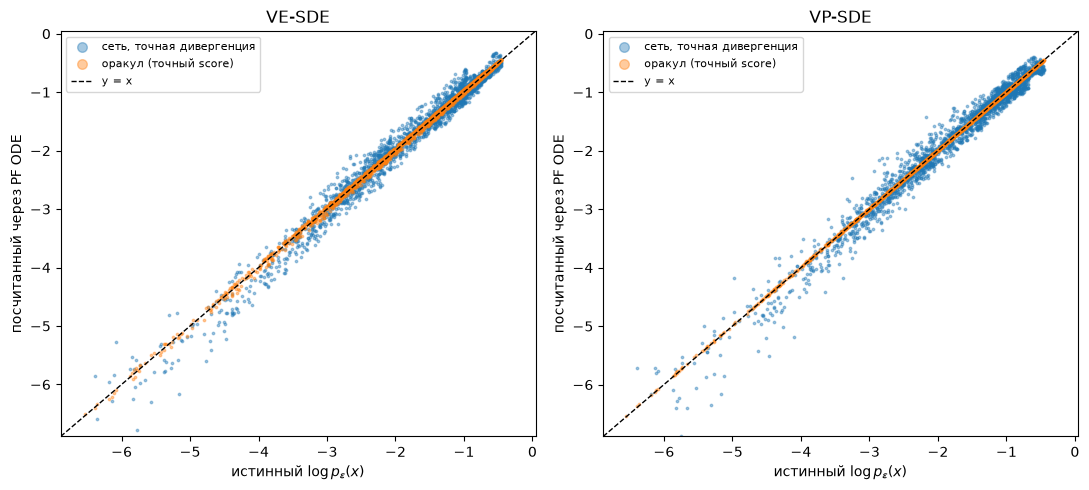

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, r) in zip(axes, ll.items()):
    t = r['true'].numpy()
    ax.scatter(t, r['model'].numpy(), s=3, alpha=0.4, label='сеть, точная дивергенция')
    ax.scatter(t, r['oracle'].numpy(), s=3, alpha=0.4, label='оракул (точный score)')
    lo, hi = np.percentile(t, 0.5) - 0.5, t.max() + 0.5
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel(r'истинный $\log p_\varepsilon(x)$'); ax.set_ylabel('посчитанный через PF ODE')
    ax.set_title(f'{name}-SDE'); ax.legend(fontsize=8, markerscale=4)
plt.tight_layout(); plt.savefig('figures/p2_loglik_scatter.png', dpi=150); plt.show()

### Точная дивергенция vs Хатчинсон

Оценка Хатчинсона несмещённая, но с одним вектором на точку у неё большой разброс. В 2D это видно явно: $v^\top A v = A_{11} + A_{22} + v_1 v_2 (A_{12} + A_{21})$, то есть на каждом шаге ошибка — $\pm(A_{12}+A_{21})$, и при фиксированном $v$ вдоль траектории эти ошибки складываются.

Усредняем по $K$ независимым векторам и смотрим, как падает разброс: ожидаем $\propto 1/\sqrt K$ (500 точек, 400 шагов).

K =   1: смещение +0.0632, разброс 1.1944
K =   4: смещение -0.0265, разброс 0.6355
K =  16: смещение +0.0021, разброс 0.3327
K =  64: смещение +0.0028, разброс 0.1471


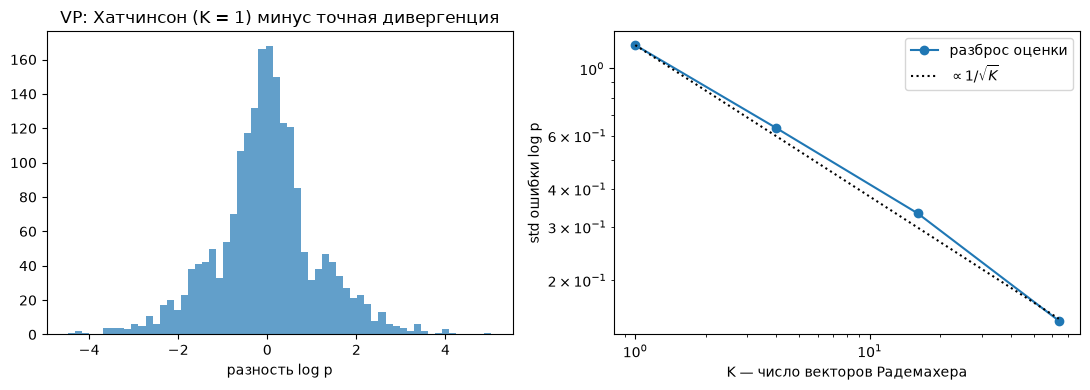

In [9]:
h = load_or_run('results/hutch_VP.pt', hutchinson_vs_k, 'VP')
for K, d in zip(h['K'], h['diff']):
    print(f'K = {K:3d}: смещение {d.mean():+.4f}, разброс {d.std():.4f}')
std = np.array([d.std() for d in h['diff']])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist((ll['VP']['model_h'] - ll['VP']['model']).numpy(), bins=60, alpha=0.7)
axes[0].set_title('VP: Хатчинсон (K = 1) минус точная дивергенция'); axes[0].set_xlabel('разность log p')
axes[1].loglog(h['K'], std, 'o-', label='разброс оценки')
axes[1].loglog(h['K'], std[0] / np.sqrt(h['K']), 'k:', label=r'$\propto 1/\sqrt{K}$')
axes[1].set_xlabel('K — число векторов Радемахера'); axes[1].set_ylabel('std ошибки log p'); axes[1].legend()
plt.tight_layout(); plt.savefig('figures/p2_hutchinson.png', dpi=150); plt.show()

## Выводы

1. **Сеть выучила score почти точно.** Относительная ошибка score в среднем по $t$ около 1% (VE) и 8% (VP), причём у VP почти вся ошибка сосредоточена в самой первой точке $t = \varepsilon$: там $\mathrm{std}(t)\approx 0.01$, и score $= -\hat\varepsilon_\theta/\mathrm{std}$ усиливает ошибку предсказания шума в 100 раз. Уже при $t \approx 0.03$ ошибка VP меньше 0.3%. На качество сэмплов это почти не влияет: на графиках сплошные линии (сеть) почти совпадают с пунктирными (оракул) при всех NFE. Значит, различия между сэмплерами — это ошибка дискретизации, а не ошибка модели.

2. **При NFE ≥ 100 сэмплеры выходят на пол метрики** (SW1 ≈ 0.03, TV мод ≈ 0.01). Доли мод, включая редкие с весом 0.05, восстанавливаются правильно. Исключение — VE + ODE: оно останавливается на SW1 ≈ 0.04, у верхней границы пола, и одинаково для сети и оракула, то есть это свойство схемы, а не модели.

3. **При малом NFE ODE и SDE ведут себя по-разному в зависимости от SDE.**
   * VP: ODE лучше SDE при NFE = 10–20 (SW1 0.08 против 0.12 при NFE = 10). Траектории ODE гладкие, и Эйлеру проще их пройти крупными шагами — это та же причина, по которой DDIM быстрее DDPM.
   * VE: наоборот, SDE лучше ODE (SW1 0.13 против 0.32 при NFE = 10). У VE коэффициент $g^2$ растёт экспоненциально, на первых шагах дрейф ODE огромен, и при грубой сетке Эйлер «перелетает». Шум в SDE частично исправляет накопленную ошибку.
   * По долям мод ODE при малом NFE лучше в обоих случаях.

4. **Log-likelihood через PF ODE работает.** С точным score оракула ошибка 0.007 (VP) и 0.03 (VE) nat на точку — это ошибка самой схемы интегрирования. С обученной сетью средний NLL совпадает с истинным с точностью до 0.01 nat, корреляция с истинным $\log p$ — 0.99; поточечная ошибка 0.13–0.14 nat — это ошибка модели.

5. **Хатчинсон: несмещённый, но шумный.** С одним вектором средний NLL почти правильный, но поточечная ошибка 0.83 nat и корреляция падает до 0.72. Разброс убывает как $1/\sqrt K$ (1.19 → 0.15 при K = 1 → 64). В 2D точная дивергенция дешёвая; Хатчинсон нужен в высокой размерности, где честно посчитать след якобиана нельзя.

**В одном предложении для постера:** обученная сеть даёт сэмплы и правдоподобие на уровне точного score; ODE выигрывает при малом NFE для VP, а для VE с экспоненциальным расписанием шума при малом NFE лучше стохастический сэмплер.